**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**08 | Frozen Final Model Evaluation and Research Synthesis**

![Completed source-verified final Essex study: seven IMUs, frozen Random Forest primary, descriptive TCN, and recorded Test evaluation](../../images/08_consolidated_workflow.svg)

**Final research question:** Following seven development stages, how well do the two **pre-frozen models** predict original model-derived e1/e3 femoral-neck finite-element (FE) strain trajectories on **four Test participants held out of model fitting** from the same Essex source cohort, and what can be learned from waveform, peak magnitude and peak location errors?

**Source and governance:** Original Essex Figshare v13 contained 1,897 trials; **1,729** had eligible source-matched IMU and FE records from **37 participants**. Original IMU trial input is 101×42 (seven six-channel lower-body sensors); published unitless FE target is 11×2 at **eleven original matched source positions**, with no FE interpolation or physical unit conversion. Subject-disjoint splits remained Training **29/1,354**, Validation **4/192** and frozen Test **4/183**. After Training-only model selection, exactly **33 development participants (1,546 trials)** were used to fit the final models.

**Frozen-before-Test selection:** Stages 05 and 07 selected the **Random Forest primary** from Training-only participant-disjoint CV (subject-balanced MAE **0.0007950**) before Test access. A **Dilated TCN secondary** was declared before Test; its recipe is retained in the [model settings](../src/essex_stage08_final.py) for descriptive waveform and peak comparison. Each execution fits both models on Training+Validation using these fixed recipes. The recorded device was Tesla T4 with CUDA for the TCN; Random Forest retained 200 trees and 210 original-channel statistical predictors. Test outcomes **did not change** the primary model.

**Final Test results:** On the 183 previously reserved trials, primary Random Forest reached **subject-balanced waveform MAE 0.0009384**; the fixed secondary Dilated TCN reached **0.0008759**, approximately **6.7% lower observed error**. Dilated TCN had lower target-wise waveform and peak-*value* error for both e1 and e3, while Random Forest had lower peak-*position* error for both. The paired, four-participant exploratory 95% bootstrap interval for **TCN − RF waveform MAE** was **[−0.0001859, +0.0000431]**, crossing zero; this does not establish a population-wide or confirmatory advantage.

**Study outputs:** The tables and figures below summarise the completed Essex analysis. The [project README](../../README.md) provides the project overview and notebook navigation.



**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/human-movement-intelligence


**01. Imports, Shared Device and Final Research Environment**

The saved execution reports a Tesla T4 CUDA GPU and PyTorch `2.11.0+cu130` for the secondary Dilated TCN. Random Forest uses scikit-learn on CPU. The targets retain the published unitless FE-model scale.


In [2]:
# ======================== 01. Imports and Environment ========================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5, label_weight="normal",
    tick_size=11, legend_size=10, figure_dpi=100, figure_size=(9, 4))

# ------------------ 4. Shared and Study Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from core.computer_device import computer_device
from essex_timebase_audit import EXPECTED_CHANNELS
from essex_temporal_regression import check_temporal_arrays
from essex_regression_baselines import (
    regression_metrics, participant_metrics, trial_predictions,
    subject_balanced_mae,
)
from essex_stage08_final import (
    EXPECTED_PRIMARY, SECONDARY, fit_frozen_primary, predict_frozen_primary,
    fit_frozen_secondary, predict_frozen_secondary, participant_bootstrap,
    paired_test_bootstrap,
)
from essex_paired_dataset import read_trial_splits, load_paired_data
from essex_stage08_final import final_model_settings

# ---------------------- 5. Source and Output Locations -----------------------
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
processed_dir = root / "data" / "processed" / "essex_femoral_neck_loading"
output_dir = study_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

# ----------------- 6. Shared Hardware Inspection and Device ------------------
device = computer_device()
DEVICE = device.type
print("Frozen primary: Random Forest | secondary: Dilated TCN")
print("Scientific output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92700
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Frozen primary: Random Forest | secondary: Dilated TCN
Scientific output directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Current Participant Splits and Model Inputs**

Read the current Notebook 04 trial assignments and the fixed final-model settings. Combine Training and Validation into Development: 33 participants and 1,546 trials. Keep the four Test participants and their 183 trials separate.


In [3]:
# ====================== 02. Current Participant Splits =======================

# --------------------- 1. Read Current Trial Assignments ---------------------
assigned = read_trial_splits(output_dir)

# -------------------- 2. Prepare Participant Split Masks ---------------------
train_mask = assigned["split"].eq("TRAIN").to_numpy()
valid_mask = assigned["split"].eq("VALIDATION").to_numpy()
test_mask = assigned["split"].eq("TEST").to_numpy()
display(
    assigned.groupby("split").agg(
        trials=("local_record_key", "size"), participants=("subject_id", "nunique")
    )
)

# ------------ 3. Load Final Model Settings and Participant Tables ------------
protocol = final_model_settings()
dev_mask = train_mask | valid_mask
dev_info = assigned.loc[dev_mask].reset_index(drop=True)
test_info = assigned.loc[test_mask].reset_index(drop=True)
print("Primary:", EXPECTED_PRIMARY, "| secondary:", SECONDARY)


,trials,participants
split,,
TEST,183,4
TRAIN,1354,29
VALIDATION,192,4


Primary: Random Forest (Stage 05 locked) | secondary: Dilated TCN


**03. Load Current Paired Arrays**

Load the current paired arrays and align them to the trial assignment table by key. Select Development signals, FE targets and source-matched indices for model fitting; Test rows are used in the prediction section.


In [4]:
# ====================== 03. Load Current Paired Arrays =======================

# -------------- 1. Install and Import the Pinned MATLAB Reader ---------------
%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"
from matio import load_from_mat

# ----------------------- 2. Load Current Paired Arrays -----------------------
paired = load_paired_data(output_dir, processed_dir, raw_dir, load_from_mat, assigned)

# ----------- 3. Select Arrays for the Required Participant Splits ------------
x_development = paired["X_full"][dev_mask]
y_development = paired["y_fe"][dev_mask]
idx_development = paired["imu_positions"][dev_mask]
print("Loaded current arrays:", {name: value.shape for name, value in paired.items()})


/usr/local/lib/python3.13/dist-packages/pandas/core/indexes/base.py:7631: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(index_like, name=name, copy=copy)


Loaded current arrays: {'X_full': (1729, 101, 42), 'X_at_fe': (1729, 11, 42), 'y_fe': (1729, 11, 2), 'imu_positions': (1729, 11)}


**04. Development and Test Overview**

Summarise Development and Test membership. The Random Forest Development matrix contains 1,546 trials with 210 IMU predictors and 22 FE outputs per trial.


In [5]:
# ===================== 04. Development and Test Overview =====================

# ------------- 1. Prepare Development and Test Participant Sets --------------
from essex_regression_baselines import trial_features, flatten_targets
development_subjects = set(dev_info["subject_id"])
reserved_subjects = set(test_info["subject_id"])

# ----------------- 2. Build Development Features and Targets -----------------
features_dev, original_feature_names = trial_features(
    x_development, EXPECTED_CHANNELS
)
targets_dev = flatten_targets(y_development)
print("Development trials:", len(dev_info), "| Test trials:", len(test_info))
print("Feature shape:", features_dev.shape, "| target shape:", targets_dev.shape)


Development trials: 1546 | Test trials: 183
Feature shape: (1546, 210) | target shape: (1546, 22)


**05. Fit the Final Models on Development Data**

Fit the primary Random Forest and secondary Dilated TCN on all Development trials using their fixed settings. The recorded models contain 200 trees and 51,986 neural parameters, respectively. Save the TCN training-loss history; Test data do not enter either fit.


In [6]:
# ===================== 05. Fit Final Development Models ======================

# --------------------- 1. Fit the Primary Random Forest ----------------------
primary, primary_features = fit_frozen_primary(
    x_development, y_development, EXPECTED_CHANNELS, protocol
)

# --------------------- 2. Fit the Secondary Dilated TCN ----------------------
secondary, secondary_scaler, final_training_history = fit_frozen_secondary(
    x_development, y_development, idx_development,
    protocol, device=device,
)

# ------------ 3. Report Model Sizes and Save the Training History ------------
secondary_parameters = sum(p.numel() for p in secondary.parameters())
print("RF estimators:", len(primary.estimators_))
print("TCN parameters:", secondary_parameters)
final_training_history.to_csv(
    output_dir / "08_development_fit_loss_history.csv", index=False
)


RF estimators: 200
TCN parameters: 51986


**06. Final Evaluation Settings**

Display the two model roles and their Development/Test trial counts. The following sections calculate predictions and replace the current Test tables and figures.


In [7]:
# ======================= 06. Final Evaluation Settings =======================

# ------------- 1. Display Final Model Roles and Evaluation Sizes -------------
display(
    pd.DataFrame(
        [
            {
                "model": EXPECTED_PRIMARY,
                "training_trials": len(dev_info),
                "test_trials": len(test_info),
                "role": "PRIMARY",
            },
            {
                "model": SECONDARY,
                "training_trials": len(dev_info),
                "test_trials": len(test_info),
                "role": "SECONDARY_DESCRIPTIVE",
            },
        ]
    )
)
print("Executing the following cells replaces the current Test tables and figures.")


,model,training_trials,test_trials,role
0,Random Forest (Stage 05 locked),1546,183,PRIMARY
1,Dilated TCN,1546,183,SECONDARY_DESCRIPTIVE


Executing the following cells replaces the current Test tables and figures.


**07. Final Test Predictions**

Predict the 183 Test trials with both fitted models at the eleven original FE positions. Save 8,052 rows covering trial, model, FE position and target in `08_test_trial_predictions.csv`.


In [8]:
# ========================= 07. Final Test Inference ==========================

# ---------------------- 1. Read the Current Test Arrays ----------------------
x_test = paired["X_full"][test_mask]
pos_test = paired["imu_positions"][test_mask]
y_test = paired["y_fe"][test_mask]
check_temporal_arrays(x_test, pos_test, y_test)

# ------------------- 2. Predict with the Two Fitted Models -------------------
prediction_primary = predict_frozen_primary(
    primary, x_test, EXPECTED_CHANNELS, primary_features
)
prediction_secondary = predict_frozen_secondary(
    secondary, secondary_scaler,
    x_test, pos_test, device=device,
)
test_predictions = {
    EXPECTED_PRIMARY: prediction_primary,
    SECONDARY: prediction_secondary,
}

# ------------------ 3. Save Source-Indexed Test Predictions ------------------
long_table = pd.concat([
    trial_predictions(
        y_test, prediction, test_info["local_record_key"],
        test_info["subject_id"], test_info["task"], model_name
    )
    for model_name, prediction in test_predictions.items()
], ignore_index=True)
long_table.to_csv(
    output_dir / "08_test_trial_predictions.csv", index=False
)
print("Current Test predictions saved.")
print("Test trial/position/target/model rows:", len(long_table))


Current Test predictions saved.
Test trial/position/target/model rows: 8052


**08. Final Test Metrics, Participant-Level Uncertainty and Activity Errors**

The predeclared primary **Random Forest** achieved subject-balanced Test MAE **0.0009384**; the fixed secondary **Dilated TCN** achieved **0.0008759** (approximately **6.7% lower observed error**). For e1, original-grid MAE was **0.0004926 / 0.0004611** (RF/TCN), and for e3 **0.0013249 / 0.0012482**. Corresponding peak-*value* MAEs were e1 **0.0008059 / 0.0007222** and e3 **0.0022999 / 0.0020255**. Peak-*position* errors showed the opposite ordering: e1 **0.9672 / 1.3497**, e3 **0.8415 / 1.1967** native FE indices.

The exploratory paired participant-cluster bootstrap difference **TCN − RF = −0.0000625** had a **95% interval [−0.0001859, +0.0000431]**, which includes zero. Four Test participants are insufficient for strong population-wide comparative claims. **Random Forest remains the preselected primary model**, irrespective of the observed secondary result.


In [9]:
# ================= 08. Predeclared Held-Out Test Evaluation ==================

# ------------ 1. Calculate Waveform, Peak and Participant Metrics ------------
rows, subject_frames, person_rows, bootstrap_rows = [], [], [], []
for model_name, prediction in test_predictions.items():
    balanced = subject_balanced_mae(y_test, prediction, test_info["subject_id"])
    for m in regression_metrics(y_test, prediction):
        rows.append(
            {
                "model": model_name,
                "role": "PRIMARY"
                if model_name == EXPECTED_PRIMARY
                else "SECONDARY_DESCRIPTIVE",
                "subject_balanced_mae": balanced,
                "test_participants": test_info["subject_id"].nunique(),
                **m,
            }
        )
    detail = participant_metrics(
        y_test,
        prediction,
        test_info["subject_id"],
        test_info["task"],
        model=model_name,
        phase="FINAL_TEST",
    )
    subject_frames.append(detail)
    for participant in sorted(reserved_subjects):
        mask = test_info["subject_id"].eq(participant).to_numpy()
        for met in regression_metrics(y_test[mask], prediction[mask]):
            person_rows.append({"model": model_name, "subject_id": participant, **met})
    bootstrap_rows.append(
        {
            "model": model_name,
            **participant_bootstrap(
                y_test, prediction, test_info["subject_id"], draws=2000, seed=2026
            ),
        }
    )

# -------------------- 2. Collect Final Evaluation Tables ---------------------
metrics_final = pd.DataFrame(rows)
subject_activity = pd.concat(subject_frames, ignore_index=True)
subject_final = pd.DataFrame(person_rows)
boot_final = pd.DataFrame(bootstrap_rows)

# --------------- 3. Compare Models with Participant Bootstrap ----------------
paired_comparison = paired_test_bootstrap(
    y_test,
    prediction_primary,
    prediction_secondary,
    test_info["subject_id"],
    draws=2000,
    seed=2026,
)
boot_final = pd.concat(
    [
        boot_final,
        pd.DataFrame(
            [
                {
                    "model": "Dilated TCN minus frozen RF",
                    "estimate": paired_comparison["difference"],
                    "bootstrap_low_95": paired_comparison["bootstrap_low_95"],
                    "bootstrap_high_95": paired_comparison["bootstrap_high_95"],
                    "participants": paired_comparison["participants"],
                    "resamples": paired_comparison["resamples"],
                    "scope": paired_comparison["scope"],
                }
            ]
        ),
    ],
    ignore_index=True,
)

# ----------------------- 4. Summarise Activity Errors ------------------------
task_final = subject_activity.groupby(
    ["model", "task", "target"], as_index=False
).agg(
    subject_mean_mae=("mae", "mean"),
    subject_mean_peak_value_mae=("peak_value_mae", "mean"),
    subject_mean_peak_index_mae=("peak_index_mae", "mean"),
    test_subjects=("subject_id", "nunique"),
    trials=("trials", "sum"),
)

# --------------------- 5. Save and Display Final Metrics ---------------------
metrics_final.to_csv(
    output_dir / "08_test_primary_secondary_metrics.csv", index=False,
)
subject_activity.to_csv(
    output_dir / "08_test_subject_activity_metrics.csv", index=False,
)
subject_final.to_csv(
    output_dir / "08_test_subject_metrics.csv", index=False,
)
task_final.to_csv(
    output_dir / "08_test_task_metrics.csv", index=False,
)
boot_final.to_csv(
    output_dir / "08_test_subject_bootstrap.csv", index=False,
)
print("Final primary model remains:", EXPECTED_PRIMARY)
print("Test metrics are descriptive and must not change model selection.")
display(metrics_final)
display(boot_final)


Final primary model remains: Random Forest (Stage 05 locked)
Test metrics are descriptive and must not change model selection.


,model,role,subject_balanced_mae,test_participants,target,mae,rmse,peak_value_mae,peak_index_mae,trials
0,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e1,0.000493,0.000760,0.000806,0.967213,183
1,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e3,0.001325,0.002065,0.002300,0.841530,183
2,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e1,0.000461,0.000713,0.000722,1.349727,183
3,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e3,0.001248,0.001930,0.002025,1.196721,183


,model,estimate,bootstrap_low_95,bootstrap_high_95,participants,resamples,scope
0,Random Forest (Stage 05 locked),0.000938,0.000616,0.001335,4,2000,exploratory_same_source_test
1,Dilated TCN,0.000876,0.000631,0.001149,4,2000,exploratory_same_source_test
2,Dilated TCN minus frozen RF,-0.000062,-0.000186,0.000043,4,2000,exploratory_not_confirmatory


**09. Final Scientific Figures and Source-Identified Waveforms**

The five committed plots are genuine final Test figures: grouped-bar e1/e3 waveform MAE, grouped-bar peak-*value* MAE, participant-specific error heterogeneity and source-identified original-grid e1 and e3 waveforms for the **lexicographically first Test trial**. Interpret their differences descriptively. The Test activity breakdown includes six activities, with uneven trial counts and some activities observed in fewer than four participants. Source FE points remain the **eleven original position indices**, not an interpolated or independently measured physiological time series.


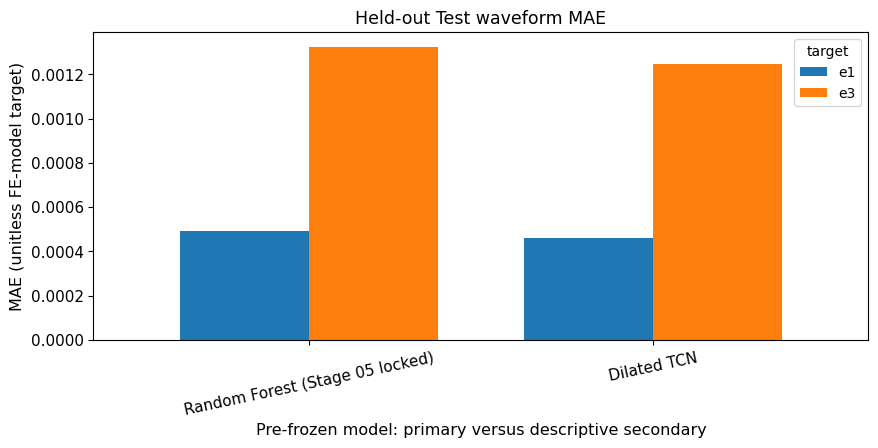

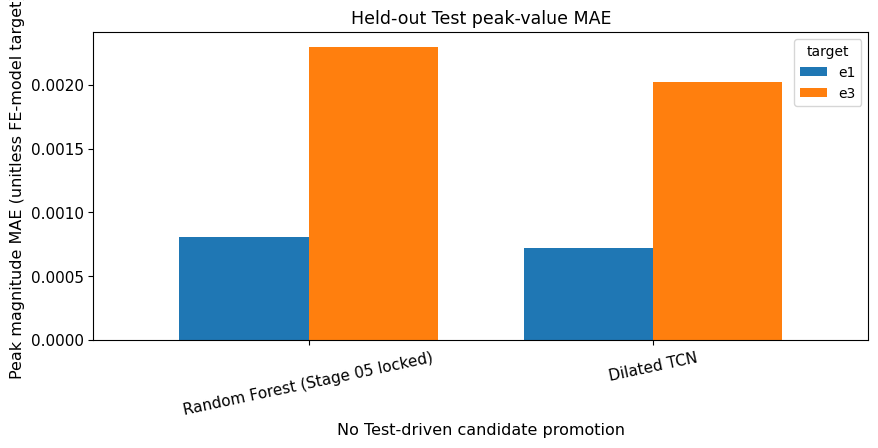

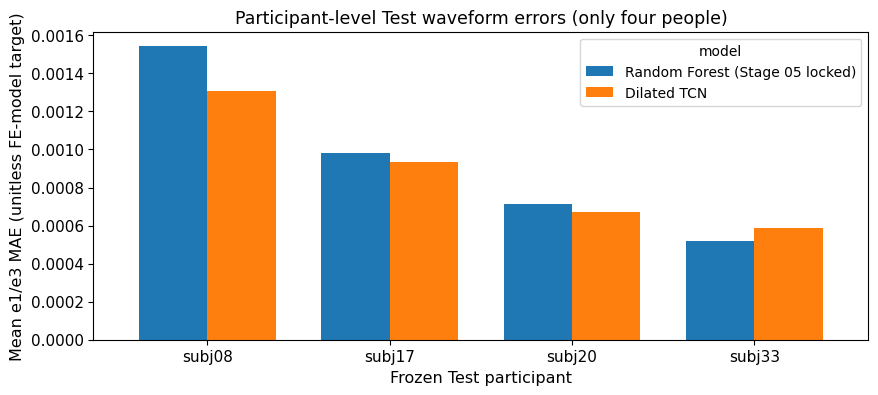

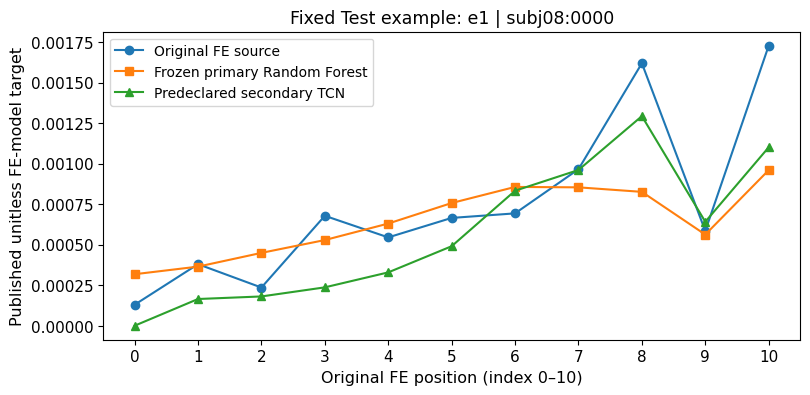

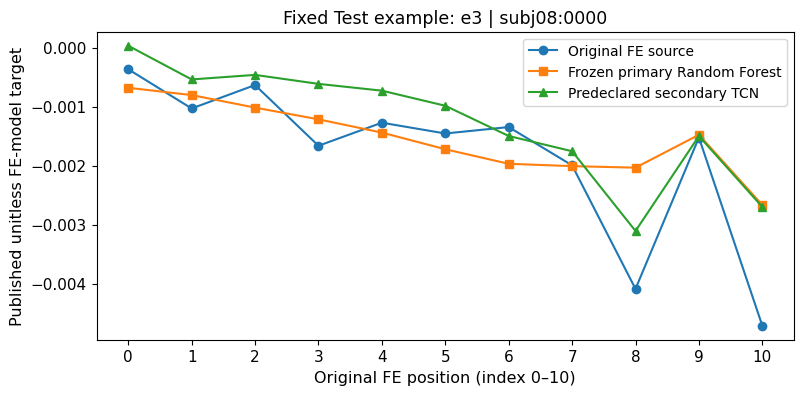

Figures are final descriptive results, never a tuning criterion.


In [10]:
# ======================== 09. Final Research Figures =========================

# --------------------- 1. Plot Held-Out Waveform Errors ----------------------
display_names = [EXPECTED_PRIMARY, SECONDARY]
chart = metrics_final.pivot(index="model", columns="target", values="mae")
chart = chart.reindex(display_names)
fig, ax = plt.subplots(figsize=(10, 4))
chart.plot.bar(ax=ax, width=0.75)
ax.set_title("Held-out Test waveform MAE")
ax.set_xlabel("Pre-frozen model: primary versus descriptive secondary")
ax.set_ylabel("MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=12)
save_figure(fig, output_dir / "08_test_waveform_mae_comparison.png")
plt.show()

# -------------------- 2. Plot Held-Out Peak-Value Errors ---------------------
peak = metrics_final.pivot(
    index="model", columns="target", values="peak_value_mae"
).reindex(display_names)
fig, ax = plt.subplots(figsize=(10, 4))
peak.plot.bar(ax=ax, width=0.75)
ax.set_title("Held-out Test peak-value MAE")
ax.set_xlabel("No Test-driven candidate promotion")
ax.set_ylabel("Peak magnitude MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=12)
save_figure(fig, output_dir / "08_test_peak_error_comparison.png")
plt.show()

# --------------------- 3. Plot Participant-Level Errors ----------------------
per_person = subject_final.groupby(
    ["subject_id", "model"], as_index=False
)["mae"].mean().pivot(
    index="subject_id", columns="model", values="mae"
).reindex(columns=display_names)
fig, ax = plt.subplots(figsize=(10, 4))
per_person.plot.bar(ax=ax, width=0.75)
ax.set_title("Participant-level Test waveform errors (only four people)")
ax.set_xlabel("Frozen Test participant")
ax.set_ylabel("Mean e1/e3 MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, output_dir / "08_test_subject_errors.png")
plt.show()

# ------------- 4. Plot Fixed Source-Identified Waveform Examples -------------
example_i = int(np.argsort(
    test_info["local_record_key"].to_numpy()
)[0])
example_key = str(test_info.iloc[example_i]["local_record_key"])
for j, target in enumerate(("e1", "e3")):
    fig, ax = plt.subplots(figsize=(9, 4))
    ticks = np.arange(11)
    ax.plot(ticks, y_test[example_i, :, j],
            marker="o", label="Original FE source")
    ax.plot(ticks, prediction_primary[example_i, :, j],
            marker="s", label="Frozen primary Random Forest")
    ax.plot(ticks, prediction_secondary[example_i, :, j],
            marker="^", label="Predeclared secondary TCN")
    ax.set_title(f"Fixed Test example: {target} | {example_key}")
    ax.set_xlabel("Original FE position (index 0–10)")
    ax.set_ylabel("Published unitless FE-model target")
    ax.set_xticks(ticks)
    ax.legend()
    save_figure(
        fig, output_dir / f"08_test_waveform_example_{target}.png"
    )
    plt.show()
print("Figures are final descriptive results, never a tuning criterion.")


**10. Results Summary and Output Download**

Display the final Test metrics and package the current predictions, participant/activity summaries, bootstrap intervals, training history and five figures. Each rerun replaces these files.


In [11]:
# ================== 10. Results Summary and Output Download ==================

# ------------------------ 1. Display Current Results -------------------------
display(metrics_final)
print("Test participants:", test_info["subject_id"].nunique())
print("Prediction rows:", len(long_table))
print("Current evaluation tables and figures saved in output/ with prefix 08_.")

# ------------------- 2. Download Current Notebook Outputs --------------------
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="08",
)


,model,role,subject_balanced_mae,test_participants,target,mae,rmse,peak_value_mae,peak_index_mae,trials
0,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e1,0.000493,0.000760,0.000806,0.967213,183
1,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e3,0.001325,0.002065,0.002300,0.841530,183
2,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e1,0.000461,0.000713,0.000722,1.349727,183
3,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e3,0.001248,0.001930,0.002025,1.196721,183


Test participants: 4
Prediction rows: 8052
Current evaluation tables and figures saved in output/ with prefix 08_.
------------------------------------------------------------------------
Notebook stage: 08
Files packaged: 12
  + 08_development_fit_loss_history.csv
  + 08_test_peak_error_comparison.png
  + 08_test_primary_secondary_metrics.csv
  + 08_test_subject_activity_metrics.csv
  + 08_test_subject_bootstrap.csv
  + 08_test_subject_errors.png
  + 08_test_subject_metrics.csv
  + 08_test_task_metrics.csv
  + 08_test_trial_predictions.csv
  + 08_test_waveform_example_e1.png
  + 08_test_waveform_example_e3.png
  + 08_test_waveform_mae_comparison.png
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_08_Outputs.zip


**11. Final Scientific Interpretation and Portfolio Handover**

**Research objective achieved at the exploratory, source-governed level.** Across Stages 01–08, the original Essex v13 MATLAB records were audited and source-aligned into **1,729 paired trials from 37 eligible participants**, with original **101×42** seven-IMU and **11×2** FE target geometry. A frozen participant-level 29/4/4 split supported Training-only model selection, diagnostic Validation, controlled three-seed robustness and recorded final evaluation on four reserved Test participants (183 trials). The work provides a reproducible research protocol and source-traceable model comparisons; it does not establish clinically verified femoral-neck loading measurements or deployment readiness.

**Preselected model and independent within-source Test.** Random Forest remained the **primary model** because it was locked before Test from the predeclared Training-only subject-balanced criterion (**0.0007950**). Both final estimators were fitted on the 33 Development participants using the fixed model settings. The primary Random Forest achieved **Test subject-balanced waveform MAE 0.0009384**. The predeclared secondary Dilated TCN achieved **0.0008759**, about **6.7% lower observed MAE** on the four participants held out of model fitting. This does **not** retrospectively make Dilated TCN the primary model; the performance gap is descriptive and its exploratory paired participant-cluster interval crosses zero.

**Biomechanical prediction trade-off.** Dilated TCN's e1/e3 original-grid waveform MAEs were **0.0004611 / 0.0012482**, compared with Random Forest **0.0004926 / 0.0013249**. TCN also had lower e1/e3 peak-*value* MAE (**0.0007222 / 0.0020255**) than Random Forest (**0.0008059 / 0.0022999**), but **worse peak-*position* accuracy**: TCN **1.3497 / 1.1967** versus RF **0.9672 / 0.8415** original FE indices. Average curve error, maximum/minimum magnitude and peak location are distinct research outcomes.

**Limits and uncertainty.** Test labels came from the **same Essex original source**, although participants were separate from Development; this is participant-held-out evaluation, **not an independent external dataset**. Only four Test participants were available. The paired TCN-minus-RF Subject-Balanced MAE difference was **−0.0000625**, with exploratory 95% bootstrap interval **[−0.0001859, +0.0000431]** (2,000 whole-participant resamples). This crosses zero and is not confirmatory statistical evidence of population superiority. No measured in-vivo strain, independent FE calibration, future-cohort validation or clinical efficacy was established. Source strain targets are **unitless, FE-model-derived** and were never interpolated or converted to microstrain.

**Study summary:** Notebooks 01–08 cover source inspection, decoding, temporal pairing, participant-level splits, classical and temporal modelling, robustness analysis and final Test evaluation. The committed outputs support an exploratory benchmark of FE-model-derived strain prediction within this source cohort.
